# FashionMNIST Image Classification

### Imports & Setups

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import v2
from torch import nn

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


## Load and Prepare Dataset


In [ ]:
training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

testing_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

### Create DataLoaders

In [ ]:
train_loader = DataLoader(training_data, batch_size=64, shuffle=True)
test_loader = DataLoader(testing_data, batch_size=64, shuffle=True)

### Explore Data Shapes

In [ ]:
image, label = next(iter(train_loader))
print(f'Feature shape: {image.shape}\nLabel shape: {label.shape}')

Feature shape: torch.Size([64, 1, 28, 28])
Label shape: torch.Size([64])


In [ ]:
print(training_data.classes)
print(len(training_data.classes))

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
10


## Define Model Architecture

In [ ]:
class MyNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 1024),
            nn.ReLU(),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = torch.flatten(x, 1)
        logits = self.linear_relu_stack(x)
        return logits

model = MyNN().to(device)
print(model)

MyNN(
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=1024, bias=True)
    (1): ReLU()
    (2): Linear(in_features=1024, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)


### Model Training & Evaluation

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model.parameters(), lr=0.01, momentum=0.7)

x_batch, y_batch = next(iter(train_loader))
print(f"Shape of image batch: {x_batch.shape}\nShape of label batch: {y_batch.shape}")

train_loss_history = [] # This will store average loss per epoch
val_loss_history = []   # This will store average loss per epoch

for epochs in range(20):
    # --------------------- Training ----------------------
    model.train()
    total_train_loss = 0.0
    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        preds = model(x_batch)
        train_loss = loss_fn(preds, y_batch)
        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()
        total_train_loss += train_loss.item()
    current_train_epoch_loss = total_train_loss / len(train_loader)
    train_loss_history.append(current_train_epoch_loss) # Append epoch average

    # --------------------- Testing ----------------------
    model.eval()
    total_test_loss = 0.0
    correct = 0.0
    with torch.no_grad():
        for x_batch, y_batch in test_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            preds = model(x_batch)
            test_loss = loss_fn(preds, y_batch)
            total_test_loss += test_loss.item()
            correct += (preds.argmax(1) == y_batch).type(torch.float).sum().item()
    current_val_epoch_loss = total_test_loss / len(test_loader)
    val_loss_history.append(current_val_epoch_loss) # Append epoch average

    print(f"Epoch {epochs + 1}: train loss = {current_train_epoch_loss:.4f}, test loss = {current_val_epoch_loss:.4f}")

print(f"\nOverall Average Train Loss across all epochs: {sum(train_loss_history) / len(train_loss_history):.4f}")
print(f"Overall Average Test Loss across all epochs: {sum(val_loss_history) / len(val_loss_history):.4f}")
print(f"Avg. Accuracy on test session for last epoch: {(correct / len(testing_data)) * 100:.4f}%")

Shape of image batch: torch.Size([64, 1, 28, 28])
Shape of label batch: torch.Size([64])
Epoch 1: train loss = 0.6110, test loss = 0.5480
Epoch 2: train loss = 0.4783, test loss = 0.4668
Epoch 3: train loss = 0.4305, test loss = 0.4446
Epoch 4: train loss = 0.4015, test loss = 0.4135
Epoch 5: train loss = 0.3800, test loss = 0.4021
Epoch 6: train loss = 0.3602, test loss = 0.3979
Epoch 7: train loss = 0.3459, test loss = 0.4117
Epoch 8: train loss = 0.3319, test loss = 0.3873
Epoch 9: train loss = 0.3202, test loss = 0.3595
Epoch 10: train loss = 0.3095, test loss = 0.3539
Epoch 11: train loss = 0.2995, test loss = 0.3511
Epoch 12: train loss = 0.2883, test loss = 0.3802
Epoch 13: train loss = 0.2817, test loss = 0.3452
Epoch 14: train loss = 0.2721, test loss = 0.3374
Epoch 15: train loss = 0.2652, test loss = 0.3450
Epoch 16: train loss = 0.2594, test loss = 0.3346
Epoch 17: train loss = 0.2526, test loss = 0.3374
Epoch 18: train loss = 0.2456, test loss = 0.3276
Epoch 19: train loss

In [ ]:
print(train_loss_history)
print(val_loss_history)

[0.6110022443253348, 0.4783450890896417, 0.43050265251827646, 0.40153241521323413, 0.3799829817434618, 0.36017970956846085, 0.34592134950321113, 0.3318562545597172, 0.3202379640581003, 0.30951383304811997, 0.29949778502683905, 0.2882741771257127, 0.2817217131445149, 0.2721118754955497, 0.26520683749843, 0.259362723289141, 0.25264285859475133, 0.2456085731638774, 0.2404644946410839, 0.23387724407382612]
[0.5479695910860778, 0.4668492524866845, 0.44456351894861573, 0.41350781006418214, 0.4021467730687682, 0.3978671077520225, 0.4116532489372666, 0.38734551837110215, 0.35952965934185466, 0.3538973868652514, 0.3510668847211607, 0.38019318897633037, 0.34523794263791124, 0.33738272262227004, 0.3449847173349113, 0.3346198129521054, 0.3373948011523599, 0.32761370732336287, 0.33889852146244354, 0.3135767038555662]


### Visualize training & validation loss

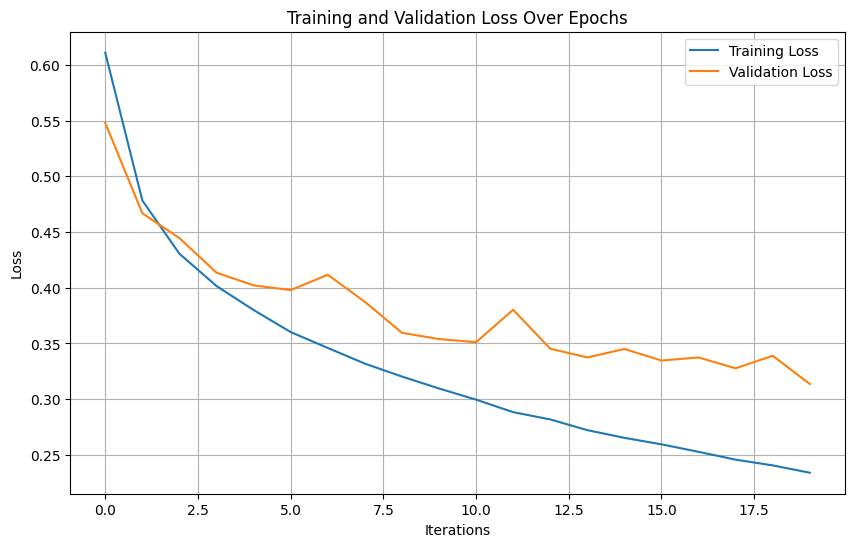

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(train_loss_history, label='Training Loss')
plt.plot(val_loss_history, label='Validation Loss')
plt.title('Training and Validation Loss Over Epochs')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### Make Predictions on Random Samples

In [ ]:
# Get 10 random indices from the test dataset
num_samples = 10
random_indices = np.random.choice(len(testing_data), num_samples, replace=False)

# Prepare lists to store images, actual labels, and predicted labels
sample_images = []
actual_labels = []

for i in random_indices:
    image, label = testing_data[i]
    sample_images.append(image)
    actual_labels.append(label)

# Stack images into a batch for model input
input_batch = torch.stack(sample_images).to(device)

# Set model to evaluation mode
model.eval()

# Make predictions
with torch.no_grad():
    logits = model(input_batch)
    probabilities = nn.functional.softmax(logits, dim=1)
    predicted_labels = torch.argmax(probabilities, dim=1)

# Convert actual_labels from numerical to class names for display
class_names = testing_data.classes
actual_class_names = [class_names[label] for label in actual_labels]
predicted_class_names = [class_names[label] for label in predicted_labels]

print("Actual Labels:", actual_class_names)
print("Predicted Labels:", predicted_class_names)

Actual Labels: ['Bag', 'Pullover', 'Trouser', 'Bag', 'Pullover', 'Dress', 'Shirt', 'Pullover', 'Ankle boot', 'Sneaker']
Predicted Labels: ['Pullover', 'Pullover', 'Trouser', 'Bag', 'Pullover', 'Dress', 'T-shirt/top', 'Pullover', 'Ankle boot', 'Sneaker']


In [ ]:
print("Logits shape:", logits.shape)
print(logits)
print(probabilities)
print(predicted_labels)

Logits shape: torch.Size([10, 10])
tensor([[ 2.2748, -1.9845,  3.9032,  1.7195,  1.9036, -7.2657,  2.8065, -4.2651,
          3.8722, -2.8446],
        [ 4.6053,  0.4825, 10.6387,  0.7220,  1.6414, -6.6108,  2.9168, -7.4668,
         -1.1887, -5.8531],
        [ 3.1384, 10.6121,  0.7826,  2.7225,  0.9630, -6.2770, -1.0030, -2.6626,
         -4.3124, -4.6994],
        [-0.3141, -3.5533,  0.1776,  0.0671, -0.5728, -3.6757,  0.8068, -3.6386,
          8.0250,  3.6625],
        [ 3.9226, -2.0123,  6.3905,  1.4955,  3.3127, -6.6035,  5.7362, -7.1234,
          0.7932, -5.8880],
        [ 3.5006,  3.8882,  1.0394,  6.8438,  0.3976, -3.8305,  0.1050, -4.5309,
         -2.3330, -4.9004],
        [ 4.6338,  4.3249,  2.8139,  3.5579,  2.8720, -7.2592,  3.3886, -4.9410,
         -2.0003, -7.6884],
        [ 2.9494,  0.8668,  5.7935, -0.5073,  0.7783, -1.9750,  2.0015, -4.6451,
         -1.7128, -3.4086],
        [-1.9179, -3.8304, -4.1475, -3.7759, -6.5954,  3.6995, -5.6738,  8.1275,
         -0.

### Visualize Random Sample Predictions

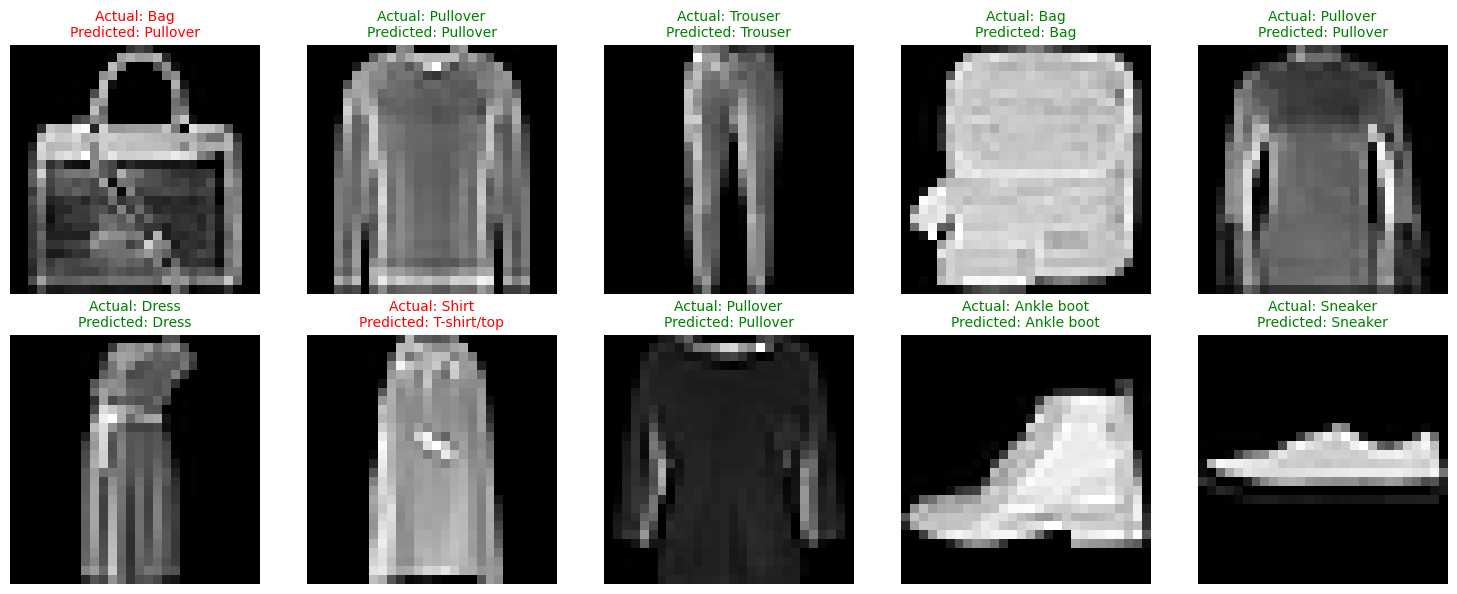

In [ ]:
fig = plt.figure(figsize=(15, 6))
for i in range(num_samples):
    plt.subplot(2, 5, i + 1) # Arrange plots in 2 rows, 5 columns
    plt.imshow(sample_images[i].squeeze().cpu().numpy(), cmap='gray')
    color = "green" if actual_class_names[i] == predicted_class_names[i] else "red"
    plt.title(f"Actual: {actual_class_names[i]}\nPredicted: {predicted_class_names[i]}", color=color, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

## Save Model

In [ ]:
torch.save(model.state_dict(), "data/model.pth")
print("Model with their parameters saved successfully!")

Model with their parameters saved successfully!


## How to Use the Saved Model in Another Python File

In [ ]:
# This code block simulates a separate Python file (e.g., `predict.py`)

import torch
from torch import nn

# Define the same model architecture as in your training script
class MyNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 1024),
            nn.ReLU(),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = torch.flatten(x, 1)
        logits = self.linear_relu_stack(x)
        return logits

# Instantiate the model
loaded_model = MyNN()

# Load the saved state dictionary
# Make sure the path to 'model.pth' is correct relative to where you run this script
loaded_model.load_state_dict(torch.load("data/model.pth"))

# Set the model to evaluation mode (important for inference)
loaded_model.eval()

print("Model loaded successfully!")

# --- Example of making a prediction with the loaded model ---
# You would typically load new image data here
# For demonstration, let's create a dummy input similar to a FashionMNIST image
dummy_input = torch.randn(1, 1, 28, 28) # Batch size 1, 1 channel, 28x28 image

with torch.no_grad(): # No need to calculate gradients during inference
    output_logits = loaded_model(dummy_input)
    probabilities = nn.functional.softmax(output_logits, dim=1)
    predicted_class = torch.argmax(probabilities, dim=1)

print(f"Dummy input shape: {dummy_input.shape}")
print(f"Output logits shape: {output_logits.shape}")
print(f"Predicted class for dummy input: {predicted_class.item()}")

# To get the class name:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print(f"Predicted class name: {class_names[predicted_class.item()]}")

Model loaded successfully!
Dummy input shape: torch.Size([1, 1, 28, 28])
Output logits shape: torch.Size([1, 10])
Predicted class for dummy input: 1
Predicted class name: Trouser
